# Desertos de cuidado LGBTQIAPN+ no estado de São Paulo

**Aquenda · Global Solution 2026.2 · Inteligência Artificial & Machine Learning · parte 2 de 2**

Giovanne Charelli Zaniboni Silva (RM 556223) · Gustavo Oliveira de Moura (RM 555827) · Lynn Bueno Rosa (RM 551102)

**Pergunta de ML:** quais municípios de São Paulo se parecem entre si quando olhamos violência notificada, distância
até o cuidado e renda, e quais formam **desertos de cuidado**? São lugares onde há violência contra pessoas
LGBTQIAPN+, mas o serviço mais próximo fica longe e a renda é baixa para chegar até ele.

É uma pergunta **não supervisionada**: não existe um rótulo "deserto" para o modelo aprender. Por isso o modelo é
**KMeans + PCA**. A parte 1 (`violencia_de_repeticao.ipynb`) responde a outra pergunta, sobre cada caso, com XGBoost.

**Dados (todos reais e públicos):**

- SINAN/DATASUS: notificações de violência interpessoal de 2022 a 2024, pelo município de residência da vítima.
- CNES/DATASUS (dez/2024): CAPS, serviço habilitado no processo transexualizador e coleta de vestígios de violência sexual.
- IBGE: população e rendimento domiciliar per capita do Censo 2022, e malha municipal.

A tabela sai de `preparar_municipios.py`; a fonte e o método estão em `dados/README.md`.

In [1]:
import warnings
from itertools import combinations, product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEMENTE = 42
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COR = {"treino": "#5B8DB8", "teste": "#E07A3F", "cv": "#7A9E5A", "neutro": "#8A8A8A"}
GRUPO_COR = ["#5B8DB8", "#E07A3F", "#7A9E5A", "#B5739D", "#C9A227", "#4D8C8C", "#8A6D4F"]

def salvar(nome):
    plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", bbox_inches="tight"); plt.show()

## 1. Os dados

In [2]:
mun = pd.read_csv("dados/municipios_sp_desertos_de_cuidado.csv", dtype={"cod7": str})
print(len(mun), "municípios")
print("com CAPS:", mun.tem_caps.sum(), "· com serviço trans habilitado:", mun.tem_trans.sum(),
      "· com coleta de violência sexual:", mun.tem_violencia_sexual.sum())
mun[["populacao", "renda_per_capita", "taxa_violencia_100mil", "taxa_violencia_lgbt_100mil",
     "dist_caps_km", "dist_trans_km", "dist_violencia_sexual_km"]].describe().T.round(1)

645 municípios
com CAPS: 285 · com serviço trans habilitado: 2 · com coleta de violência sexual: 49


,count,mean,std,min,25%,50%,75%,max
populacao,645.0,68854.6,464421.0,907.0,5466.0,13163.0,38324.0,11451999.0
renda_per_capita,645.0,1543.4,330.2,888.5,1348.7,1487.8,1677.5,3884.6
taxa_violencia_100mil,645.0,175.7,148.4,0.0,70.7,137.2,236.0,941.6
taxa_violencia_lgbt_100mil,645.0,7.1,8.9,0.0,0.0,5.1,9.8,73.2
dist_caps_km,645.0,11.7,11.9,0.0,0.0,12.6,20.5,44.1
dist_trans_km,645.0,148.5,73.3,0.0,92.9,149.0,201.9,405.5
dist_violencia_sexual_km,645.0,39.2,24.6,0.0,22.8,36.1,52.9,125.8


### As variáveis do agrupamento

As seis variáveis seguem o pitch do Aquenda: violência notificada, distância até o serviço e renda.

| Variável | O que mede |
|---|---|
| `taxa_violencia_lgbt_100mil` | notificações com vítima LGBTQIAPN+ por 100 mil moradores, por ano (2022–2024) |
| `taxa_violencia_100mil` | todas as notificações de violência interpessoal por 100 mil, por ano |
| `dist_caps_km` | distância até o município mais próximo com CAPS (0 se tem) |
| `dist_trans_km` | distância até o município mais próximo com serviço habilitado do processo transexualizador |
| `dist_violencia_sexual_km` | distância até o município mais próximo com coleta de vestígios de violência sexual |
| `renda_per_capita` | rendimento domiciliar per capita médio (Censo 2022) |

Todas são muito assimétricas, com poucos municípios com valores enormes. Por isso passam por `log(1 + x)` e depois por
padronização (média 0, desvio 1). Sem isso, o KMeans, que mede distância, seria dominado pela variável de maior escala.

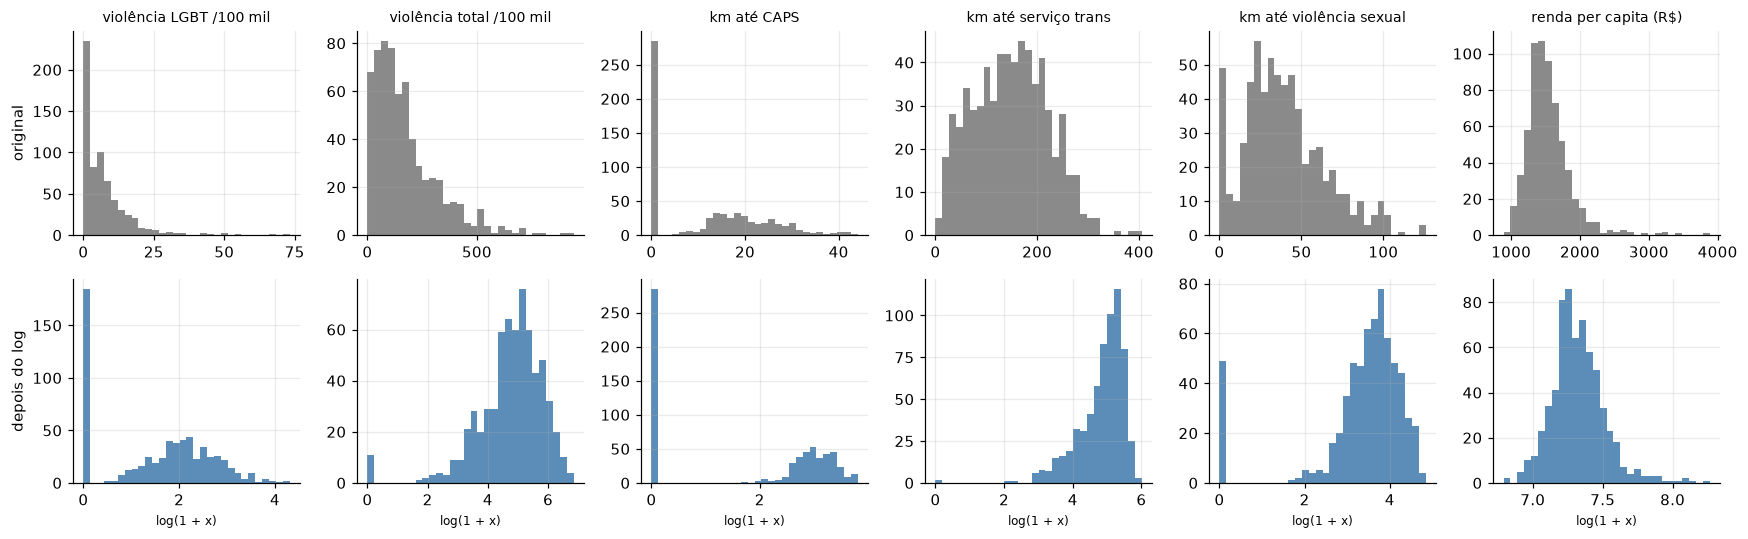

In [3]:
VARS = ["taxa_violencia_lgbt_100mil", "taxa_violencia_100mil", "dist_caps_km", "dist_trans_km",
        "dist_violencia_sexual_km", "renda_per_capita"]
NOMES = {"taxa_violencia_lgbt_100mil": "violência LGBT /100 mil", "taxa_violencia_100mil": "violência total /100 mil",
         "dist_caps_km": "km até CAPS", "dist_trans_km": "km até serviço trans", "dist_violencia_sexual_km": "km até violência sexual",
         "renda_per_capita": "renda per capita (R$)"}
X_todo = np.log1p(mun[VARS])

fig, axes = plt.subplots(2, 6, figsize=(16, 5))
for j, v in enumerate(VARS):
    axes[0, j].hist(mun[v], bins=30, color=COR["neutro"]); axes[0, j].set_title(NOMES[v], fontsize=9)
    axes[1, j].hist(X_todo[v], bins=30, color=COR["treino"]); axes[1, j].set_xlabel("log(1 + x)", fontsize=8)
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("depois do log")
salvar("10_distribuicoes_municipios")

## 2. Preparação e divisão treino/teste

Mesmo sem rótulo, separamos **20% dos municípios para teste**, escolhidos ao acaso. Padronização, PCA e KMeans
são ajustados **só no treino**. Os municípios do teste entram no fim, distribuídos pelos grupos que o modelo já tinha.
Se os grupos forem bons, eles também separam bem municípios que o modelo nunca viu.

In [4]:
X_tr, X_te, mun_tr, mun_te = train_test_split(X_todo, mun, test_size=0.2, random_state=SEMENTE)
print(f"treino: {len(X_tr)} municípios · teste: {len(X_te)} municípios")
pd.DataFrame({"treino": X_tr.mean(), "teste": X_te.mean()}).T.round(2)

treino: 516 municípios · teste: 129 municípios


,taxa_violencia_lgbt_100mil,taxa_violencia_100mil,dist_caps_km,dist_trans_km,dist_violencia_sexual_km,renda_per_capita
treino,1.57,4.78,1.71,4.83,3.34,7.33
teste,1.34,4.65,1.60,4.84,3.41,7.31


### PCA: quanto cabe em poucas dimensões

O PCA gira as seis variáveis padronizadas em componentes sem correlação entre si, do que mais explica variação para
o que menos explica. Usar 2 ou 3 componentes tira ruído e permite desenhar os grupos num plano.

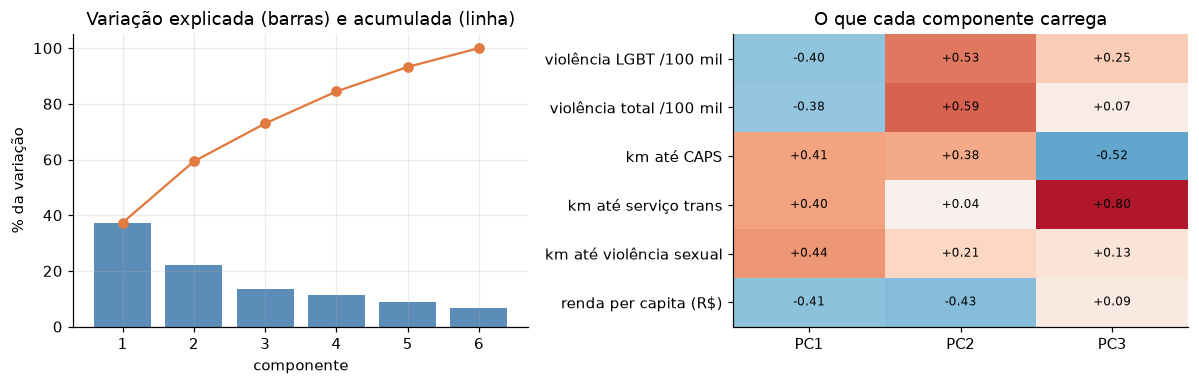

variação acumulada: [ 37.4  59.3  72.9  84.4  93.2 100. ]


In [5]:
pca_vis = make_pipeline(StandardScaler(), PCA(random_state=SEMENTE)).fit(X_tr)
pca = pca_vis.named_steps["pca"]
var = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(range(1, 7), var * 100, color=COR["treino"]); ax[0].plot(range(1, 7), np.cumsum(var) * 100, "o-", color=COR["teste"])
ax[0].set_xlabel("componente"); ax[0].set_ylabel("% da variação"); ax[0].set_title("Variação explicada (barras) e acumulada (linha)")
cargas = pd.DataFrame(pca.components_[:3].T, index=[NOMES[v] for v in VARS], columns=["PC1", "PC2", "PC3"])
im = ax[1].imshow(cargas.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"); ax[1].grid(False)
ax[1].set_xticks(range(3), cargas.columns); ax[1].set_yticks(range(6), cargas.index)
for i in range(6):
    for j in range(3):
        ax[1].text(j, i, f"{cargas.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("O que cada componente carrega")
salvar("11_pca")
print("variação acumulada:", np.round(np.cumsum(var) * 100, 1))

## 3. Modelo e hiperparâmetros

**Por que KMeans + PCA.** A pergunta não tem rótulo. O KMeans agrupa municípios parecidos, e o centro de cada grupo
pode ser lido como um "perfil": por exemplo, longe de tudo, renda baixa e violência notificada. O PCA tira a redundância
entre as distâncias, que andam juntas. Os outros modelos da lista (XGBoost, Random Forest, MLP, LSTM) precisam de um
rótulo que aqui não existe.

**Grade: 36 combinações de 3 hiperparâmetros**, cada uma com validação cruzada de 5 partes **só no treino**:

| Hiperparâmetro | Valores |
|---|---|
| `n_clusters` (k) | 2, 3, 4, 5, 6, 7 |
| componentes do PCA | 2, 3, sem redução (as 6 variáveis) |
| `init` | `k-means++`, `random` |

**Como avaliar sem rótulo.** Em cada parte da validação, o modelo é ajustado em 4/5 do treino. Depois, distribui nos
grupos o 1/5 que ficou de fora. Medimos:

- **silhueta** (de −1 a 1): o quanto cada município está mais perto do próprio grupo do que do grupo vizinho. É
  calculada sempre no mesmo espaço (as 6 variáveis padronizadas), para comparar combinações com e sem PCA;
- **estabilidade (ARI)**: se dois ajustes em partes diferentes do treino agrupam os mesmos municípios do mesmo jeito.
  1 é idêntico, 0 é acaso.

In [6]:
GRADE = {"k": [2, 3, 4, 5, 6, 7], "componentes": [2, 3, None], "init": ["k-means++", "random"]}
cv = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def modelo(k, comp, init):
    passos = [StandardScaler()] + ([PCA(n_components=comp, random_state=SEMENTE)] if comp else [])
    return make_pipeline(*passos, KMeans(n_clusters=k, init=init, n_init=10, random_state=SEMENTE))

def espaco(pipe, X):
    return pipe.named_steps["standardscaler"].transform(X)  # o mesmo espaço para todas as combinações

def silhueta(pipe, X):
    rot = pipe.predict(X)
    return silhouette_score(espaco(pipe, X), rot) if len(set(rot)) > 1 else np.nan

linhas = []
for k, comp, init in product(GRADE["k"], GRADE["componentes"], GRADE["init"]):
    s_tr, s_val, rotulos = [], [], []
    for i_fit, i_val in cv.split(X_tr):
        pipe = modelo(k, comp, init).fit(X_tr.iloc[i_fit])
        s_tr.append(silhueta(pipe, X_tr.iloc[i_fit])); s_val.append(silhueta(pipe, X_tr.iloc[i_val]))
        rotulos.append(pipe.predict(X_tr))
    ari = np.mean([adjusted_rand_score(a, b) for a, b in combinations(rotulos, 2)])
    linhas.append({"k": k, "componentes": comp or 6, "init": init, "silhueta_treino": np.mean(s_tr),
                   "silhueta_val": np.mean(s_val), "silhueta_val_dp": np.std(s_val), "estabilidade_ari": ari})
grade = pd.DataFrame(linhas)
print(len(grade), "combinações avaliadas")
grade.sort_values("silhueta_val", ascending=False).head(10).round(3)

36 combinações avaliadas


,k,componentes,init,silhueta_treino,silhueta_val,silhueta_val_dp,estabilidade_ari
28,6,6,k-means++,0.276,0.265,0.023,0.894
22,5,6,k-means++,0.268,0.262,0.018,0.838
23,5,6,random,0.266,0.258,0.023,0.923
29,6,6,random,0.275,0.255,0.024,0.851
16,4,6,k-means++,0.259,0.254,0.024,0.925
17,4,6,random,0.260,0.254,0.024,0.926
11,3,6,random,0.245,0.243,0.025,0.967
10,3,6,k-means++,0.245,0.243,0.025,0.963
35,7,6,random,0.262,0.230,0.032,0.741
34,7,6,k-means++,0.258,0.229,0.030,0.760


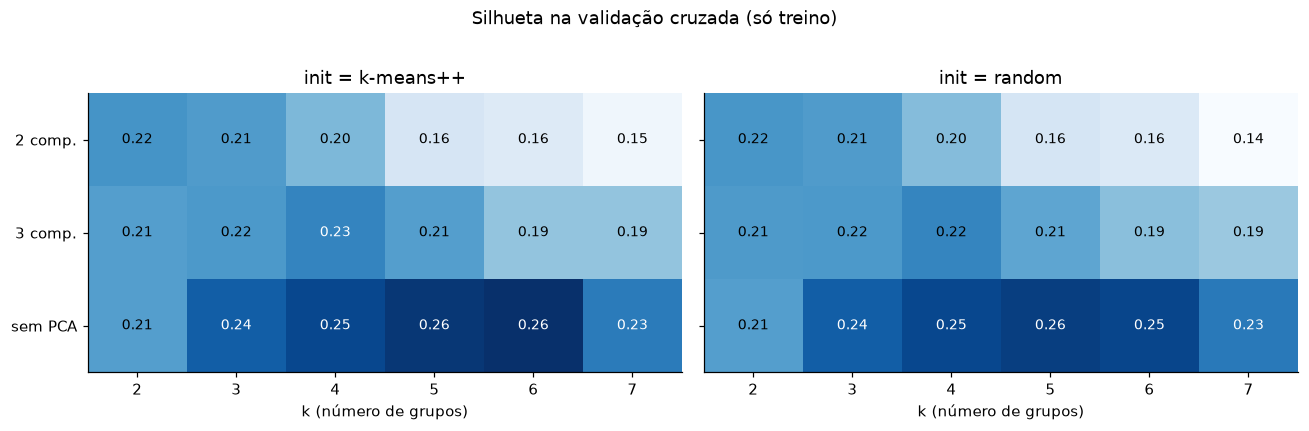

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, init in zip(axes, GRADE["init"]):
    t = grade[grade.init == init].pivot(index="componentes", columns="k", values="silhueta_val")
    ax.imshow(t.values, cmap="Blues", vmin=grade.silhueta_val.min(), vmax=grade.silhueta_val.max(), aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(t.columns)), t.columns); ax.set_yticks(range(len(t.index)), [f"{c} comp." if c < 6 else "sem PCA" for c in t.index])
    ax.set_xlabel("k (número de grupos)"); ax.set_title(f"init = {init}")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if t.values[i, j] > grade.silhueta_val.quantile(0.7) else "black")
fig.suptitle("Silhueta na validação cruzada (só treino)", y=1.02)
salvar("12_grade_silhueta")

### Escolha da combinação

Duas regras, decididas antes de olhar o teste:

1. **k de 3 para cima.** O objetivo é priorizar onde levar cuidado: precisamos de pelo menos "bem servido",
   "intermediário" e "deserto". Com k = 2, o KMeans quase sempre só separa a região metropolitana do resto.
2. Entre esses, a **maior silhueta na validação** com **estabilidade de pelo menos 0,8**. Um agrupamento que muda
   conforme a amostra não serve para decidir onde agir.

In [8]:
candidatas = grade[(grade.k >= 3) & (grade.estabilidade_ari >= 0.8)]
escolhida = candidatas.loc[candidatas.silhueta_val.idxmax()]
K, COMP, INIT = int(escolhida.k), (None if escolhida.componentes == 6 else int(escolhida.componentes)), escolhida.init
print("melhor da grade inteira:", grade.loc[grade.silhueta_val.idxmax(), ["k", "componentes", "init", "silhueta_val", "estabilidade_ari"]].to_dict())
print("escolhida:", {"k": K, "componentes": COMP or "sem PCA", "init": INIT},
      f"silhueta validação {escolhida.silhueta_val:.3f}, estabilidade {escolhida.estabilidade_ari:.2f}")

melhor da grade inteira: {'k': 6, 'componentes': 6, 'init': 'k-means++', 'silhueta_val': 0.2648764522898688, 'estabilidade_ari': 0.8943239623932497}
escolhida: {'k': 6, 'componentes': 'sem PCA', 'init': 'k-means++'} silhueta validação 0.265, estabilidade 0.89


## 4. Resultados em treino e teste

O modelo escolhido é ajustado em todo o treino. Os municípios do teste são distribuídos pelos grupos que ele já tinha.
Medidas: silhueta (maior é melhor), Davies-Bouldin (menor é melhor; compara a dispersão dentro dos grupos com a
distância entre eles) e inércia média por município (distância ao quadrado até o centro do grupo).

In [9]:
final = modelo(K, COMP, INIT).fit(X_tr)
rot_tr, rot_te = final.predict(X_tr), final.predict(X_te)
km = final.named_steps["kmeans"]

def medidas(X, rot):
    Z = espaco(final, X)
    Zm = Z if COMP is None else final.named_steps["pca"].transform(Z)
    return {"silhueta": silhouette_score(Z, rot), "Davies-Bouldin (menor é melhor)": davies_bouldin_score(Z, rot),
            "inércia por município": ((Zm - km.cluster_centers_[rot]) ** 2).sum(axis=1).mean()}

tabela = pd.DataFrame({"treino": medidas(X_tr, rot_tr), "teste": medidas(X_te, rot_te)}).T.round(3)
tabela

,silhueta,Davies-Bouldin (menor é melhor),inércia por município
treino,0.274,1.307,2.522
teste,0.225,1.393,2.677


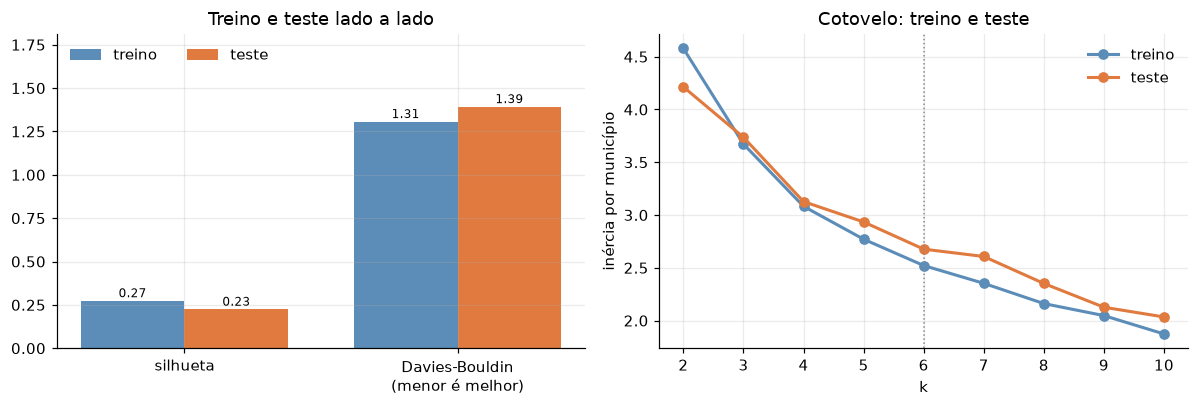

k,2,3,4,5,6,7,8,9,10
treino,4.578,3.673,3.083,2.771,2.522,2.353,2.161,2.047,1.873
teste,4.214,3.736,3.127,2.935,2.677,2.607,2.352,2.127,2.034
sil_treino,0.227,0.246,0.258,0.264,0.274,0.245,0.244,0.247,0.243
sil_teste,0.213,0.181,0.220,0.216,0.225,0.196,0.202,0.221,0.223


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
mostrar = ["silhueta", "Davies-Bouldin (menor é melhor)"]
w = 0.38; x = np.arange(len(mostrar))
for i, (nome, cor) in enumerate([("treino", COR["treino"]), ("teste", COR["teste"])]):
    v = tabela.loc[nome, mostrar].values
    ax[0].bar(x + (i - 0.5) * w, v, w, color=cor, label=nome)
    for xi, vi in zip(x + (i - 0.5) * w, v):
        ax[0].text(xi, vi + 0.02, f"{vi:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(x, ["silhueta", "Davies-Bouldin\n(menor é melhor)"]); ax[0].legend(frameon=False, ncol=2, loc="upper left")
ax[0].set_ylim(0, max(tabela[mostrar].max()) * 1.3); ax[0].set_title("Treino e teste lado a lado")
# cotovelo: inércia por município no treino e no teste, para cada k (mesmo PCA e init)
cot = []
for k in range(2, 11):
    m = modelo(k, COMP, INIT).fit(X_tr)
    def inercia(X):
        Z = espaco(m, X); Z = Z if COMP is None else m.named_steps["pca"].transform(Z)
        return ((Z - m.named_steps["kmeans"].cluster_centers_[m.predict(X)]) ** 2).sum(axis=1).mean()
    cot.append({"k": k, "treino": inercia(X_tr), "teste": inercia(X_te),
                "sil_treino": silhueta(m, X_tr), "sil_teste": silhueta(m, X_te)})
cot = pd.DataFrame(cot).set_index("k")
ax[1].plot(cot.index, cot.treino, "o-", color=COR["treino"], lw=2, label="treino")
ax[1].plot(cot.index, cot.teste, "o-", color=COR["teste"], lw=2, label="teste")
ax[1].axvline(K, color=COR["neutro"], ls=":", lw=1)
ax[1].set_xlabel("k"); ax[1].set_ylabel("inércia por município"); ax[1].legend(frameon=False); ax[1].set_title("Cotovelo: treino e teste")
salvar("13_treino_vs_teste_kmeans")
cot.round(3).T

### Overfitting no agrupamento

No KMeans, o overfitting aparece quando k cresce demais. A inércia do treino sempre cai (cada município ganha um
centro mais perto), mas os grupos passam a separar detalhes da amostra que não se repetem. O sinal é a silhueta do
teste caindo e a distância entre treino e teste aumentando.

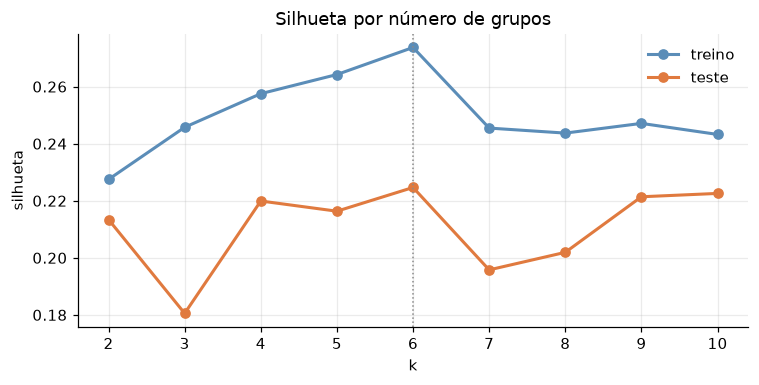

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cot.index, cot.sil_treino, "o-", color=COR["treino"], lw=2, label="treino")
ax.plot(cot.index, cot.sil_teste, "o-", color=COR["teste"], lw=2, label="teste")
ax.axvline(K, color=COR["neutro"], ls=":", lw=1)
ax.set_xlabel("k"); ax.set_ylabel("silhueta"); ax.legend(frameon=False); ax.set_title("Silhueta por número de grupos")
salvar("14_silhueta_por_k")

## 5. Os grupos: quem é deserto de cuidado

In [12]:
mun_tr = mun_tr.assign(grupo=rot_tr, parte="treino"); mun_te = mun_te.assign(grupo=rot_te, parte="teste")
todos = pd.concat([mun_tr, mun_te])
perfil = todos.groupby("grupo").agg(municipios=("municipio", "size"), populacao=("populacao", "sum"),
                                    **{v: (v, "median") for v in VARS})
# Nome de cada grupo, pela mediana. Deserto de cuidado, como no pitch: há violência notificada, o cuidado está longe
# e a renda é baixa. Ou seja, maior soma de postos em distância, em renda baixa e em notificação LGBT.
dist = perfil[["dist_caps_km", "dist_trans_km", "dist_violencia_sexual_km"]].rank().sum(axis=1)
nota_deserto = dist + (-perfil["renda_per_capita"]).rank() + perfil["taxa_violencia_lgbt_100mil"].rank()
polo = dist.idxmin()
deserto = nota_deserto.drop(polo).idxmax()
nomes = {}
for g in perfil.index:
    if g == polo:
        nomes[g] = "polo de serviços"
    elif g == deserto:
        nomes[g] = "deserto de cuidado"
    elif perfil.loc[g, "taxa_violencia_lgbt_100mil"] == 0:
        nomes[g] = "longe e sem notificação" + (" (sem CAPS)" if perfil.loc[g, "dist_caps_km"] > 0 else " (com CAPS)")
    elif perfil.loc[g, "dist_violencia_sexual_km"] == 0:
        nomes[g] = "rede regional"
    else:
        nomes[g] = "intermediário"
perfil.insert(0, "nome", perfil.index.map(nomes))
# o deserto em vermelho, para saltar aos olhos; os outros em tons distintos e mais calmos
COR_NOME = {"deserto de cuidado": "#D1495B", "polo de serviços": "#2E86AB", "rede regional": "#7A9E5A",
            "intermediário": "#A7A7A7", "longe e sem notificação (sem CAPS)": "#E9A23B",
            "longe e sem notificação (com CAPS)": "#9B72B0"}
todos["nome"] = todos.grupo.map(nomes)
perfil.sort_values("dist_trans_km").round(1)

,nome,municipios,populacao,taxa_violencia_lgbt_100mil,taxa_violencia_100mil,dist_caps_km,dist_trans_km,dist_violencia_sexual_km,renda_per_capita
grupo,,,,,,,,,
1,polo de serviços,55,19827955,8.0,236.0,0.0,31.3,15.9,1628.8
5,intermediário,162,9639007,5.8,165.4,0.0,141.7,37.0,1587.2
3,rede regional,44,10849644,6.3,181.6,0.0,143.7,0.0,1989.0
2,deserto de cuidado,177,1730567,9.3,185.2,19.9,147.9,40.7,1429.3
0,longe e sem notificação (sem CAPS),147,932929,0.0,85.4,19.8,175.2,42.3,1371.8
4,longe e sem notificação (com CAPS),60,1431136,0.0,18.7,0.0,194.9,48.9,1556.7


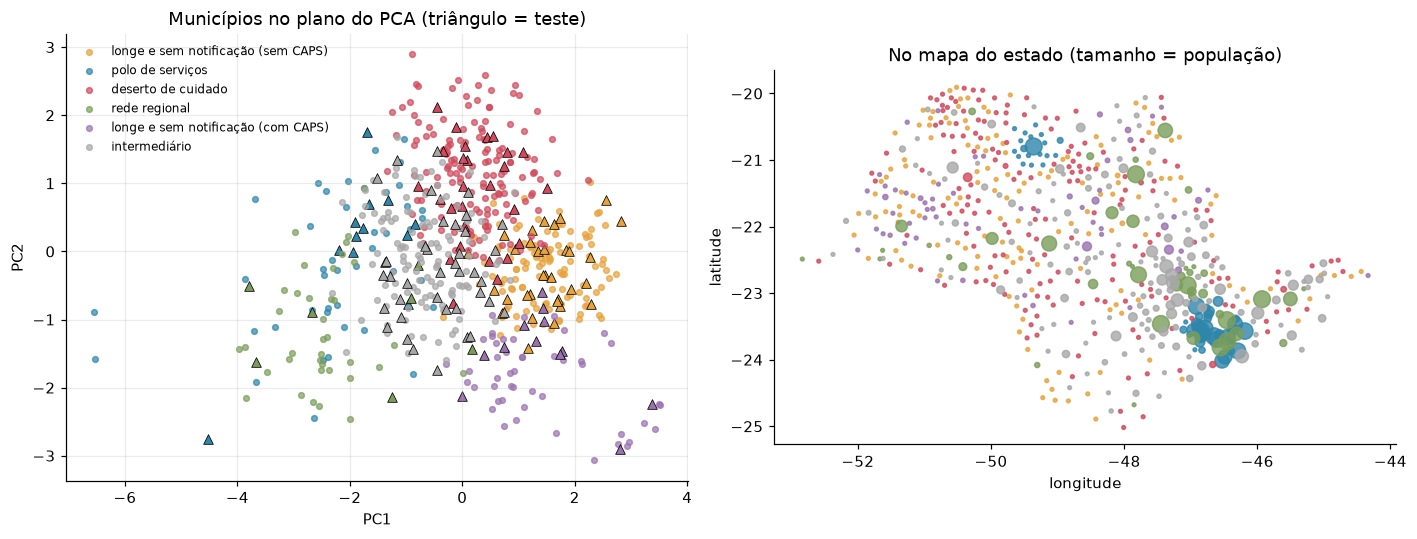

In [13]:
Z_tr = final.named_steps["standardscaler"].transform(X_tr); Z_te = final.named_steps["standardscaler"].transform(X_te)
p2 = PCA(n_components=2, random_state=SEMENTE).fit(Z_tr)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for g in sorted(nomes):
    c = COR_NOME.get(nomes[g], GRUPO_COR[g % len(GRUPO_COR)])
    a = p2.transform(Z_tr[rot_tr == g]); b = p2.transform(Z_te[rot_te == g])
    ax[0].scatter(a[:, 0], a[:, 1], s=14, color=c, alpha=0.7, label=nomes[g])
    ax[0].scatter(b[:, 0], b[:, 1], s=40, color=c, marker="^", edgecolor="black", linewidth=0.5)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Municípios no plano do PCA (triângulo = teste)")
for g in sorted(nomes):
    t = todos[todos.grupo == g]
    ax[1].scatter(t.lon, t.lat, s=np.clip(t.populacao / 4000, 6, 120), color=COR_NOME.get(nomes[g], GRUPO_COR[g % len(GRUPO_COR)]), alpha=0.8, label=nomes[g])
ax[1].set_xlabel("longitude"); ax[1].set_ylabel("latitude"); ax[1].set_aspect("equal"); ax[1].grid(False)
ax[1].set_title("No mapa do estado (tamanho = população)")
salvar("15_grupos_pca_e_mapa")

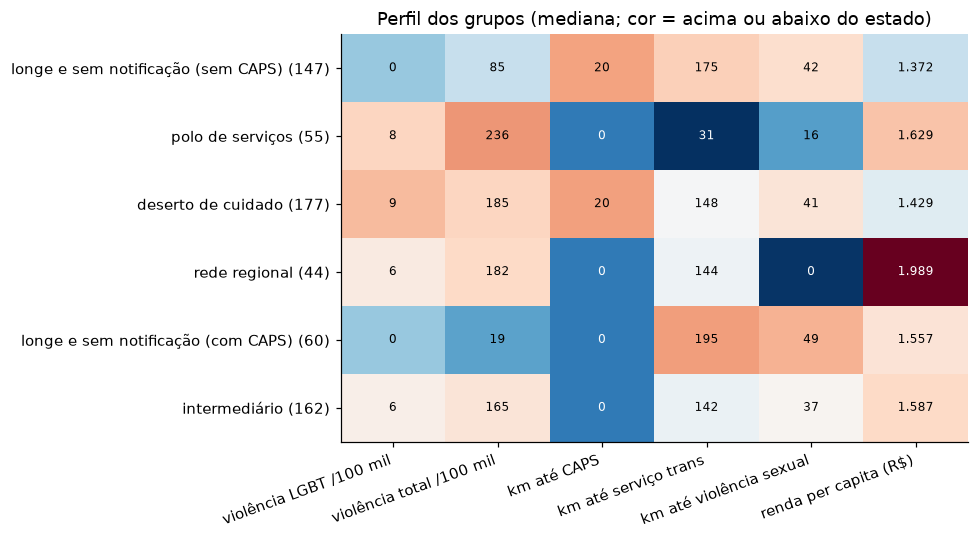

In [14]:
z = (perfil[VARS] - todos[VARS].median()) / todos[VARS].std()
fig, ax = plt.subplots(figsize=(9, 0.6 * len(z) + 1.4))
ax.imshow(z.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(VARS)), [NOMES[v] for v in VARS], rotation=20, ha="right")
ax.set_yticks(range(len(z)), [f"{perfil.loc[g, 'nome']} ({perfil.loc[g, 'municipios']})" for g in z.index])
for i, g in enumerate(z.index):
    for j, v in enumerate(VARS):
        ax.text(j, i, f"{perfil.loc[g, v]:,.0f}".replace(",", "."), ha="center", va="center", fontsize=8,
                color="white" if abs(z.loc[g, v]) > 0.9 else "black")
ax.set_title("Perfil dos grupos (mediana; cor = acima ou abaixo do estado)")
salvar("16_perfil_dos_grupos")

In [15]:
deserto = todos[todos.nome == "deserto de cuidado"].sort_values("violencia_lgbt", ascending=False)
mediana_estado = todos[VARS].median()
print(f"{len(deserto)} municípios no deserto de cuidado, {deserto.populacao.sum():,.0f} moradores".replace(",", "."))
print(f"notificações com vítima LGBTQIAPN+ nesses municípios (2022–2024): {deserto.violencia_lgbt.sum()}")
deserto[["municipio", "populacao", "violencia_lgbt", "taxa_violencia_lgbt_100mil", "dist_caps_km", "dist_trans_km",
         "dist_violencia_sexual_km", "renda_per_capita"]].head(15).round(1).reset_index(drop=True)

177 municípios no deserto de cuidado. 1.730.567 moradores
notificações com vítima LGBTQIAPN+ nesses municípios (2022–2024): 573


,municipio,populacao,violencia_lgbt,taxa_violencia_lgbt_100mil,dist_caps_km,dist_trans_km,dist_violencia_sexual_km,renda_per_capita
0,Birigui,118979,23,6.4,28.2,115.1,101.6,1733.0
1,Ipeúna,6831,15,73.2,12.0,174.1,26.0,1722.5
2,Mongaguá,61951,15,8.1,15.5,47.3,31.0,1287.8
3,Piquete,12490,13,34.7,17.9,191.2,40.4,1322.0
4,Santa Lúcia,7149,12,56.0,6.4,166.0,18.3,1388.3
5,Icém,7819,12,51.2,19.4,51.1,51.1,1574.2
6,Tremembé,51173,12,7.8,16.4,132.6,19.1,1946.4
7,Alumínio,17301,12,23.1,5.9,65.4,18.7,1523.4
8,José Bonifácio,36633,10,9.1,40.8,54.6,39.8,1697.3
9,Pirapora do Bom Jesus,18370,9,16.3,10.4,45.1,23.8,1199.2


## 6. Conclusão para quem usa a cidade

Os números estão no `RELATORIO_ML.md`, que lê as tabelas acima. Em resumo:

- Os **desertos de cuidado** são municípios onde há violência notificada contra pessoas LGBTQIAPN+, mas não há CAPS
  no próprio município, o serviço especializado mais próximo está a dezenas ou centenas de quilômetros e a renda é baixa
  para a viagem.
- O grupo **longe e sem notificação** preocupa de outro jeito. Ali quase não há registro de violência contra pessoas
  LGBTQIAPN+. Isso não quer dizer que não haja violência: falta onde notificar e quem pergunte. Morar ali e ser
  LGBTQIAPN+ quer dizer depender de deslocamento, de ônibus intermunicipal e de dinheiro para chegar a um ambulatório trans.
- Para o **Aquenda**, a lista serve para priorizar onde mapear ONGs e serviços parceiros, onde oferecer orientação por
  teleatendimento e onde a Defensoria e o transporte para consulta fazem mais diferença. Para o poder público, indica onde
  habilitar o próximo serviço.
- **Limites:** a distância é em linha reta, entre os centros dos municípios. Notificação baixa pode querer dizer pouca
  violência ou pouco serviço para notificar, e num deserto de cuidado é mais provável a segunda. Os grupos descrevem
  o estado hoje; não são previsão.

In [16]:
todos[["cod7", "municipio", "nome", "parte"] + VARS].sort_values(["nome", "municipio"]).to_csv(
    "modelo/municipios_por_grupo.csv", index=False, encoding="utf-8")
grade.round(4).to_csv("modelo/grade_kmeans.csv", index=False)
print("grupos e grade salvos em ml/modelo/")

grupos e grade salvos em ml/modelo/
